In [2]:
import scanpy as sc

In [3]:
human = sc.read_h5ad("/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/submission/20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")

In [4]:
adata = human

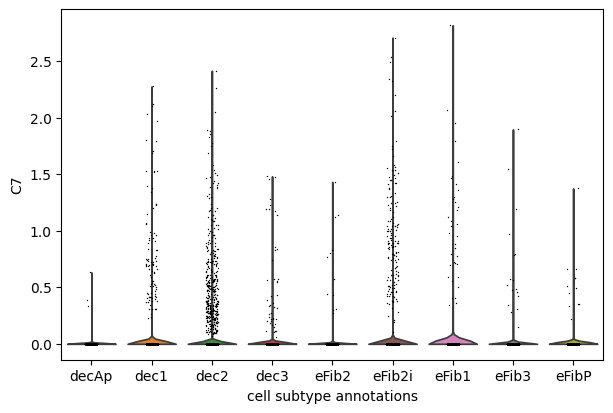

In [5]:
sc.pl.violin(adata, "C7", layer=  'log1p',use_raw = False, groupby="cell_subtype_annotations")

In [35]:
import scanpy as sc

fib = adata[adata.obs["cell_subtype_annotations"].isin(
    ["eFib1", "eFib2", "eFib2i", "eFib3", "eFibP"])].copy()

In [5]:
sc.tl.rank_genes_groups(fib, groupby="cell_subtype_annotations",
                        method="wilcoxon", layer="log1p", use_raw=False)

for g in ["eFib1", "eFib2", "eFib2i", "eFib3", "eFibP"]:
    print(g, sc.get.rank_genes_groups_df(fib, group=g).head(20), sep="\n")

eFib1
         names     scores  logfoldchanges          pvals      pvals_adj
0       Col3a1  36.705608        1.307057  5.943271e-295  3.337939e-291
1       Col1a2  34.708519        1.589476  5.860267e-264  1.645661e-260
2     Adamtsl1  33.185062        1.859475  1.768328e-241  3.972609e-238
3        Meis2  33.177547        1.301201  2.269748e-241  4.780373e-238
4        Celf2  32.724640        1.278843  6.970068e-235  1.304874e-231
5       Cacnb2  32.056046        3.933597  1.808203e-225  2.769673e-222
6         Dlc1  30.803085        1.292366  2.382581e-208  3.211529e-205
7       Abca8a  29.720739        4.788463  4.143541e-194  4.654302e-191
8        Prkg1  29.425049        1.895063  2.626447e-190  2.765813e-187
9       Col1a1  27.648718        1.590689  2.891672e-168  2.498553e-165
10        Nfib  27.529463        2.485931  7.796659e-167  6.568296e-164
11        Pid1  27.070848        1.811938  2.170951e-161  1.741826e-158
12       Zfpm2  26.130466        5.052246  1.643425e-150  

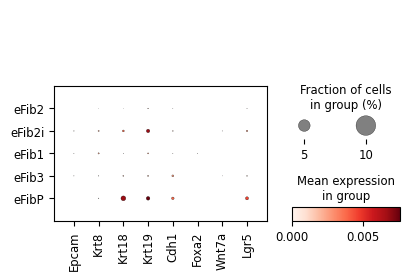

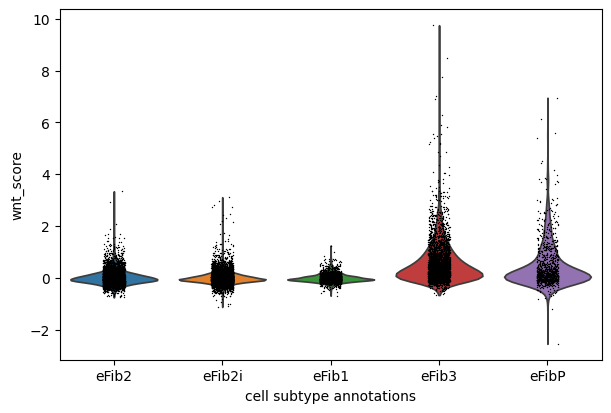

In [6]:
import scanpy as sc

fibs = ["eFib1","eFib2","eFib2i","eFib3","eFibP"]
fib = adata[adata.obs["cell_subtype_annotations"].isin(fibs)].copy()

# 1. Contamination check: are epithelial markers actually enriched in eFib3?
epi = ["Epcam","Krt8","Krt18","Krt19","Cdh1","Foxa2","Wnt7a","Lgr5"]
sc.pl.dotplot(fib, [g for g in epi if g in adata.var_names],
              groupby="cell_subtype_annotations", layer="log1p", use_raw=False)
# expectation if eFib3 is REAL stroma: these stay flat/low across all fib subtypes

# 2. Canonical Wnt-target module score (is eFib3 broadly Wnt-active, not just Lef1?)
wnt_targets = ["Lef1","Axin2","Tcf7","Nkd1","Notum","Wif1","Tcf7l2","Rnf43","Znrf3"]
sc.tl.score_genes(fib, [g for g in wnt_targets if g in adata.var_names],
                  score_name="wnt_score")
sc.pl.violin(fib, "wnt_score", groupby="cell_subtype_annotations")
# Axin2 is the gold-standard target — if it tracks Lef1 in eFib3, the Wnt story firms up

# 3. Doublet / ambient sanity check specifically on eFib3
#    (run Scrublet on the raw counts of the full object; check eFib3's doublet rate
#     and whether high-epithelial-content cells concentrate there)

# 4. If you still have the epithelial clusters in the FULL object:
#    correlate eFib3's mean profile against luminal epithelium vs stroma pseudobulk.
#    eFib3 should correlate with stroma, NOT epithelium — that kills the contamination reading cleanly.

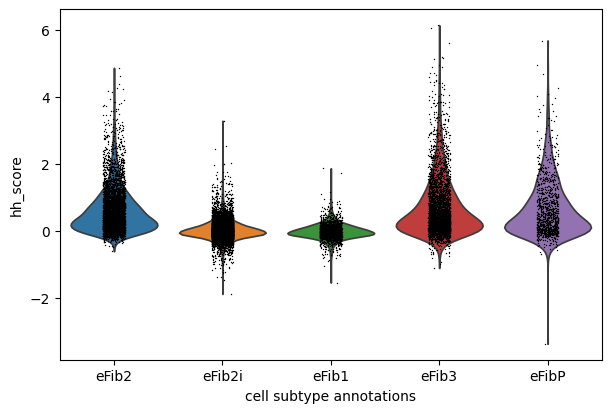

In [7]:
hh_stroma = ["Ptch1","Ptch2","Gli1","Gli2","Gli3","Smo","Hhip","Nr2f2","Bmp2","Hand2"]
sc.tl.score_genes(fib, [g for g in hh_stroma if g in adata.var_names], score_name="hh_score")
sc.pl.violin(fib, "hh_score", groupby="cell_subtype_annotations")
# Gli1 is the gold-standard readout of ACTIVE Hh signaling (pure Gli target, like Axin2 is for Wnt).
# If eFib2 is high for Gli1 + Nr2f2, not just Ptch1, the "Hh-receiver" call is solid.

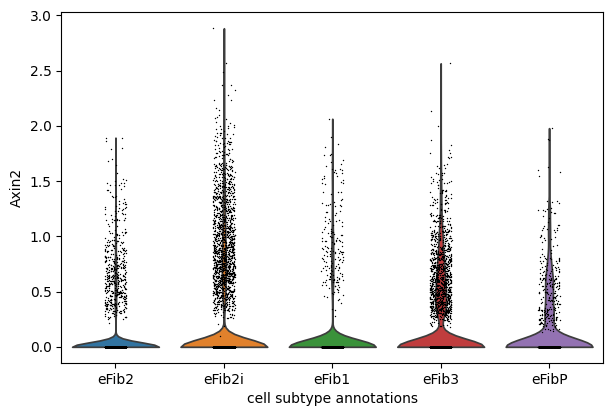

In [10]:
sc.pl.violin(fib, "Axin2", layer=  'log1p',use_raw = False, groupby="cell_subtype_annotations")


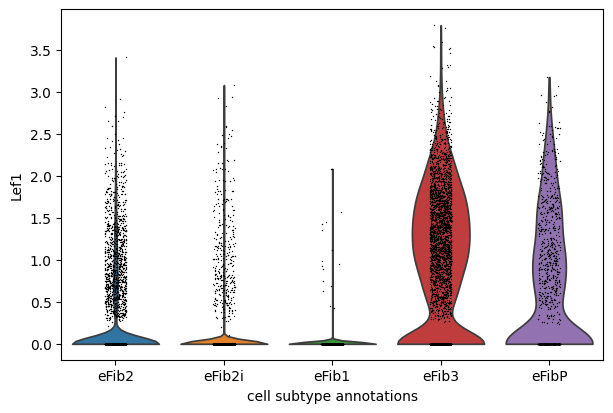

In [11]:
sc.pl.violin(fib, "Lef1", layer=  'log1p',use_raw = False, groupby="cell_subtype_annotations")


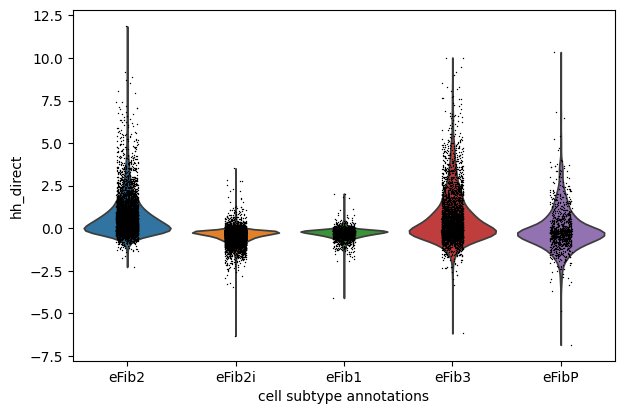

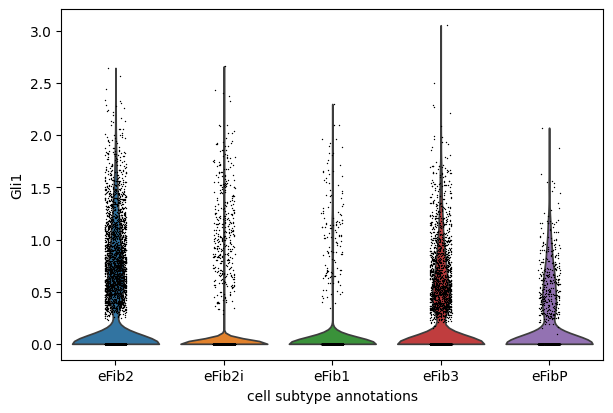

In [12]:
# Direct Hh targets only — the clean "is the pathway ON" readout
hh_direct = ["Gli1","Ptch1","Ptch2","Hhip"]   # drop Smo/Gli2/Gli3 (leaky), drop Bmp2/Hand2/Nr2f2 (downstream stromal, not Hh-specific)
sc.tl.score_genes(fib, [g for g in hh_direct if g in adata.var_names], score_name="hh_direct")
sc.pl.violin(fib, "hh_direct", groupby="cell_subtype_annotations")

# Also eyeball Gli1 alone — gold-standard target, but dropout-prone in droplet data,
# so trust its PRESENCE, not its absence. The 3–4 gene module is more robust than Gli1 solo.
sc.pl.violin(fib, "Gli1", groupby="cell_subtype_annotations", use_raw=False, layer="log1p")

/tmp/ipykernel_560374/3056716302.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for g, sub in df.groupby("cell_subtype_annotations"):


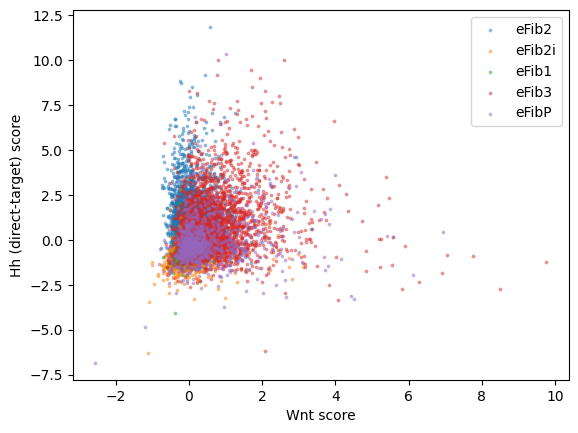

In [13]:
import matplotlib.pyplot as plt
df = fib.obs[["cell_subtype_annotations","wnt_score","hh_direct"]]
for g, sub in df.groupby("cell_subtype_annotations"):
    plt.scatter(sub["wnt_score"], sub["hh_direct"], s=3, alpha=.4, label=g)
plt.xlabel("Wnt score"); plt.ylabel("Hh (direct-target) score"); plt.legend()

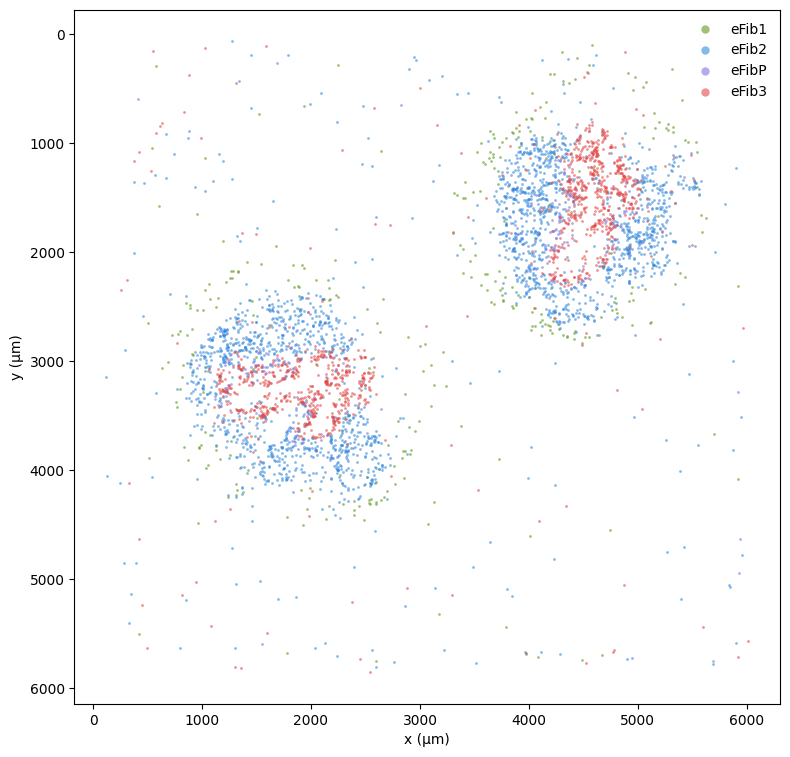

In [5]:
import matplotlib.pyplot as plt

# uninduced timepoint + the four layers you care about
mask = (adata.obs["timepoint"] == "uninduced") & \
       adata.obs["cell_subtype_annotations"].isin(["eFib1","eFib2","eFibP","eFib3"])
sub = adata[mask]

# draw outermost -> innermost so z-order matches your hypothesis
order  = ["eFib1","eFib2","eFibP","eFib3"]
colors = {"eFib1":"#639922","eFib2":"#378ADD","eFibP":"#7F77DD","eFib3":"#E24B4A"}

fig, ax = plt.subplots(figsize=(8,8))
for ct in order:
    m = sub.obs["cell_subtype_annotations"] == ct
    ax.scatter(sub.obs.loc[m, "x_um_dbscan"], sub.obs.loc[m, "y_um_dbscan"],
               s=4, alpha=0.6, c=colors[ct], label=ct, linewidths=0)

ax.set_aspect("equal")     # non-negotiable for spatial — otherwise the layering is distorted
ax.invert_yaxis()          # image coords usually run y-down; drop this line if it looks flipped
ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
ax.legend(markerscale=3, frameon=False)
plt.tight_layout(); plt.show()

In [7]:
~adata.obs['x_um_dbscan'].isna()

CAATGACTCCCACAGG    False
TAATTCCCAGCTGTTA    False
TAACCAGGTGGCCACT     True
AGGTTACTCGTCTAAG    False
CAATACGTCACCTGTC     True
                    ...  
AATGGCTGTTCGGACC    False
CACACAAAGCTGGTGA    False
TACCTCGAGCGATGAC    False
AGGGCCTCAAGAGAGA     True
TTCCACGTCTCTCAAT     True
Name: x_um_dbscan, Length: 43052, dtype: bool

In [8]:
import numpy as np
from sklearn.cluster import DBSCAN
from scipy.stats import mannwhitneyu
from scipy.spatial import cKDTree

obs = adata.obs.loc[
    (~adata.obs['x_um_dbscan'].isna()) & 
    (adata.obs["timepoint"] == "uninduced") &
    adata.obs["cell_subtype_annotations"].isin(["eFib1","eFib2","eFibP","eFib3"]),
    ["x_um_dbscan","y_um_dbscan","cell_subtype_annotations"]].copy()

obs["blob"] = DBSCAN(eps=250, min_samples=15).fit_predict(obs[["x_um_dbscan","y_um_dbscan"]].values)
real = [b for b in obs.blob.unique() if b != -1]
left = min(real, key=lambda b: obs.loc[obs.blob==b,"x_um_dbscan"].mean())
s = obs[obs.blob == left].copy()
print(s.cell_subtype_annotations.value_counts())      # <-- CHECK eFibP n FIRST

cx, cy = s.x_um_dbscan.mean(), s.y_um_dbscan.mean()
s["r"] = np.hypot(s.x_um_dbscan-cx, s.y_um_dbscan-cy)
r = {ct: s.r[s.cell_subtype_annotations==ct].values for ct in ["eFib2","eFibP","eFib3"]}
print("eFibP outside eFib3:", mannwhitneyu(r["eFibP"], r["eFib3"], alternative="greater").pvalue)
print("eFibP inside eFib2 :", mannwhitneyu(r["eFibP"], r["eFib2"], alternative="less").pvalue)

coords = s[["x_um_dbscan","y_um_dbscan"]].values; lab = s.cell_subtype_annotations.values.astype(str)
def mean_cos(L):
    P,A,C = coords[L=="eFibP"], coords[L=="eFib2"], coords[L=="eFib3"]
    if len(P)<5 or len(A)==0 or len(C)==0: return np.nan
    vA = A[cKDTree(A).query(P)[1]]-P; vC = C[cKDTree(C).query(P)[1]]-P
    vA/=np.linalg.norm(vA,axis=1,keepdims=True); vC/=np.linalg.norm(vC,axis=1,keepdims=True)
    return (vA*vC).sum(1).mean()
rng = np.random.default_rng(0); o = mean_cos(lab)
null = np.array([mean_cos(rng.permutation(lab)) for _ in range(1000)])
print(f"cosine={o:.3f}  p={np.nanmean(null<=o):.3f}")

cell_subtype_annotations
eFib2     1049
eFib3      569
eFib1      130
eFibP      102
decAp        0
dec3         0
dec2         0
dec1         0
eFib2i       0
Name: count, dtype: int64
eFibP outside eFib3: 0.3275089362913689
eFibP inside eFib2 : 1.6259623209631473e-31


/tmp/ipykernel_593680/958157772.py:29: RuntimeWarning: invalid value encountered in divide
  vA/=np.linalg.norm(vA,axis=1,keepdims=True); vC/=np.linalg.norm(vC,axis=1,keepdims=True)


cosine=-0.058  p=0.014


In [21]:
import numpy as np, scanpy as sc
from scipy.spatial import cKDTree

coords = adata.obs[["x_um_dbscan","y_um_dbscan"]].values
lab = adata.obs["cell_subtype_annotations"].values.astype(str)
tree = cKDTree(coords); nbr = tree.query(coords, k=16)[1][:,1:]
f2, f3 = (lab[nbr]=="eFib2").mean(1), (lab[nbr]=="eFib3").mean(1)
interface = np.minimum(f2, f3) > 0.2

zone = np.full(len(lab), "other", dtype=object)
zone[(lab=="eFib2") & ~interface] = "eFib2_core"
zone[(lab=="eFib3") & ~interface] = "eFib3_core"
zone[interface & np.isin(lab, ["eFib2","eFib3","eFibP"])] = "boundary"
adata.obs["zone"] = zone; print(adata.obs["zone"].value_counts())

# THE organizer test: what does the seam express that the cores don't?
sc.tl.rank_genes_groups(adata, "zone", groups=["boundary"], reference="rest",
                        method="wilcoxon", layer="log1p", use_raw=False)
bd = sc.get.rank_genes_groups_df(adata, group="boundary")
# scan the top hits for SECRETED LIGANDS — Wnt4/Wnt5a/Wnt11, Rspo1-3, Bmp2/4/7,
# Fgf*, Dkk*, Sfrp*, Shh/Ihh — and Notch targets Hes1/Hey1/Heyl/Nrarp.

zone
eFib2_core    2034
eFib3_core    1009
boundary       553
other          495
Name: count, dtype: int64


In [27]:
print(bd.head(30))

            names    scores  logfoldchanges         pvals     pvals_adj
0             Fn1  9.124646        0.686492  7.197090e-20  1.862732e-15
1            Map2  9.078033        0.615201  1.105544e-19  1.862732e-15
2            Lef1  8.786082        0.896914  1.548666e-18  1.739565e-14
3          Synpo2  8.236830        0.532561  1.768340e-16  1.489738e-12
4           Pkdcc  7.447272        0.776639  9.528989e-14  6.422157e-10
5        Tmem132c  7.335637        0.622911  2.206694e-13  1.239353e-09
6   2600014E21Rik  7.088654        0.674699  1.354232e-12  5.704362e-09
7          Ppfia2  6.928856        0.577467  4.242558e-12  1.499133e-08
8           Gria4  6.712535        0.496120  1.912713e-11  5.371218e-08
9             Wt1  6.678001        0.498745  2.422226e-11  6.278782e-08
10           Ano1  6.487504        0.535107  8.727036e-11  2.100597e-07
11          Cntn3  6.463210        0.854288  1.025051e-10  2.302812e-07
12        Cacna1e  6.402388        0.709798  1.529652e-10  3.221

In [23]:
bpts = coords[zone=="boundary"]
adata.obs["dist_boundary"] = cKDTree(bpts).query(coords)[0]
# spearman(dist_boundary, target_module_score) within each core; a source predicts negative decay

In [31]:
s = adata.copy()

In [32]:
import numpy as np, scanpy as sc
e2 = s[s.obs.cell_subtype_annotations == "eFib2"].copy()
e2.obs["pos"] = np.where(e2.obs["zone"] == "boundary", "interface", "core")
sc.tl.rank_genes_groups(e2, "pos", groups=["interface"], reference="core",
                        method="wilcoxon", layer="log1p", use_raw=False)
print(sc.get.rank_genes_groups_df(e2, group="interface").head(20))

            names    scores  logfoldchanges         pvals  pvals_adj
0        Tmem132c  5.995560        0.790654  2.027859e-09   0.000017
1            Lef1  5.949523        1.443074  2.689243e-09   0.000018
2           Cdh11  5.675058        0.521588  1.386418e-08   0.000067
3             Fn1  5.384780        0.596601  7.253337e-08   0.000222
4            Ano1  5.127128        0.664765  2.941964e-07   0.000826
5         Galntl6  5.023846        1.680222  5.064677e-07   0.001313
6           Rxfp1  4.913760        0.644805  8.934618e-07   0.002095
7           Pkdcc  4.905353        0.973203  9.325935e-07   0.002095
8            Heg1  4.721759        0.572607  2.338136e-06   0.004377
9           Mast4  4.565636        0.835781  4.979813e-06   0.008390
10           Map2  4.490177        0.429986  7.116397e-06   0.011419
11         Slc6a2  4.476466        1.276623  7.588862e-06   0.011521
12  C430049B03Rik  4.383694        2.105124  1.166839e-05   0.015728
13        Cacna1e  4.308634       

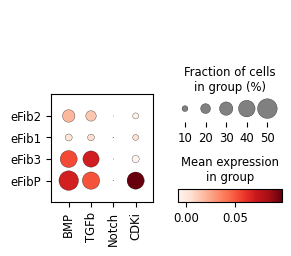

In [37]:
brake_response = {
  "BMP":   ["Id1","Id2","Id3","Smad6","Smad7","Bambi"],
  "TGFb":  ["Serpine1","Skil","Smad7","Junb"],
  "Notch": ["Hey1","Hes1","Nrarp","Heyl"],
  "CDKi":  ["Cdkn1a","Cdkn1b","Cdkn2a","Cdkn2b"],
}
for name, genes in brake_response.items():
    sc.tl.score_genes(fib, [g for g in genes if g in fib.var_names], score_name=name)
sc.pl.dotplot(fib, list(brake_response), groupby="cell_subtype_annotations",
              layer="log1p", use_raw=False)   # is any of these eFib3-high?

In [36]:
s_genes_mouse = [
    "Mcm5","Pcna","Tyms","Fen1","Mcm2","Mcm4","Rrm1","Ung","Gins2","Mcm6",
    "Cdca7","Dtl","Prim1","Uhrf1","Cenpu","Hells","Rfc2","Rpa2","Nasp","Rad51ap1",
    "Gmnn","Wdr76","Slbp","Ccne2","Ubr7","Pold3","Msh2","Atad2","Rad51","Rrm2",
    "Cdc45","Cdc6","Exo1","Tipin","Dscc1","Blm","Casp8ap2","Usp1","Clspn","Pola1",
    "Chaf1b","Brip1","E2f8",
]

g2m_genes_mouse = [
    "Hmgb2","Cdk1","Nusap1","Ube2c","Birc5","Tpx2","Top2a","Ndc80","Cks2","Nuf2",
    "Cks1b","Mki67","Tmpo","Cenpf","Tacc3","Pimreg","Smc4","Ccnb2","Ckap2l","Ckap2",
    "Aurkb","Bub1","Kif11","Anp32e","Tubb4b","Gtse1","Kif20b","Hjurp","Cdca3","Jpt1",
    "Cdc20","Ttk","Cdc25c","Kif2c","Rangap1","Ncapd2","Dlgap5","Cdca2","Cdca8","Ect2",
    "Kif23","Hmmr","Aurka","Psrc1","Anln","Lbr","Ckap5","Cenpe","Ctcf","Nek2",
    "G2e3","Gas2l3","Cbx5","Cenpa",
]

# intersect with your genes FIRST — anything not in var_names is silently dropped,
# which quietly deflates the score. Check the match count before trusting the result.
s_use   = [g for g in s_genes_mouse   if g in fib.var_names]
g2m_use = [g for g in g2m_genes_mouse if g in fib.var_names]
print(f"matched S: {len(s_use)}/{len(s_genes_mouse)}   G2M: {len(g2m_use)}/{len(g2m_genes_mouse)}")

sc.tl.score_genes_cell_cycle(fib, s_genes=s_use, g2m_genes=g2m_use)
print(fib.obs.groupby("cell_subtype_annotations")["phase"].value_counts(normalize=True))

matched S: 43/43   G2M: 54/54
cell_subtype_annotations  phase
eFib2                     G1       0.944129
                          S        0.042776
                          G2M      0.013095
eFib1                     G1       0.923754
                          S        0.052786
                          G2M      0.023460
eFib3                     G1       0.956487
                          S        0.037873
                          G2M      0.005641
eFibP                     G2M      0.518349
                          S        0.481651
                          G1       0.000000
Name: proportion, dtype: float64


/tmp/ipykernel_593680/672695497.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(fib.obs.groupby("cell_subtype_annotations")["phase"].value_counts(normalize=True))


In [40]:
import pandas as pd
from scipy.stats import chi2_contingency, fisher_exact
d = fib.obs[fib.obs.cell_subtype_annotations.isin(["eFib1","eFib2","eFib3"])].copy()
d["cycling"] = d["phase"] != "G1"
ct = pd.crosstab(d["cell_subtype_annotations"], d["cycling"]); print(ct)
print("3-way p =", chi2_contingency(ct)[1])
print("eFib2 vs eFib3 p =", fisher_exact(ct.loc[["eFib2","eFib3"]].values)[1])

cycling                   False  True 
cell_subtype_annotations              
eFib2                      2163    128
eFib1                       315     26
eFib3                      1187     54
3-way p = 0.04602285216411351
eFib2 vs eFib3 p = 0.1296190967995888


In [43]:
s = fib

In [44]:
import numpy as np, statsmodels.formula.api as smf
cx, cy = s.obs["x_um_dbscan"].mean(), s.obs["y_um_dbscan"].mean()
s.obs["r"] = np.hypot(s.obs["x_um_dbscan"]-cx, s.obs["y_um_dbscan"]-cy)
s.obs["cycling"] = (s.obs["phase"] != "G1").astype(int)
m = smf.logit("cycling ~ r", data=s.obs).fit(disp=0)   # ALL cells, incl eFibP
print(m.summary().tables[1])
# luminal-brake prediction: POSITIVE, significant coefficient on r
# (cycling rises with distance from center ≈ distance from epithelium)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.1478      0.175    -12.265      0.000      -2.491      -1.805
r          -2.576e-06   9.84e-05     -0.026      0.979      -0.000       0.000


In [45]:
!ls /n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/submission

20251008_Cevrim_Human_All_Cells.h5ad
20251008_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
20251008_Cevrim_XMens_All_Cells.h5ad
20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
20251008_Cevrim_XMens_Only_Fib_Dec_Cells_pt_batch.h5ad
filtered
leiden_sweep_submission_fibdec.ipynb
results
Untitled1.ipynb
Untitled.ipynb


In [46]:
full = sc.read_h5ad("/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/submission/20251008_Cevrim_XMens_All_Cells.h5ad")

In [49]:
import scanpy as sc, numpy as np

# 1. subset the full object to uninduced
full_un = full[full.obs["timepoint"] == "uninduced"].copy()

# 2. transfer fine fibroblast labels by shared barcode (exact; no kNN needed)
overlap = adata.obs_names.isin(full_un.obs_names).mean()
print(f"adata barcodes found in full_un: {overlap:.1%}")   # <- must be high; if ~0, see below

COARSE = "cell_type_annotations"   # your coarse column in full

fine = full_un.obs[COARSE].astype(str)                          # start: everything coarse-labeled (strings)
mapped = adata.obs["cell_subtype_annotations"].astype(str).reindex(full_un.obs_names)  # <- .astype(str) kills the categorical
fine.loc[mapped.notna()] = mapped[mapped.notna()]               # overwrite fibroblasts with fine labels
full_un.obs["fine"] = fine.astype("category")                   # categorical only at the end
print(full_un.obs["fine"].value_counts())

adata barcodes found in full_un: 100.0%
fine
endometrial fibroblasts    5222
epithelial cells           5052
eFib2                      2291
eFib3                      1241
smooth muscle cells        1041
immune cells                788
perimetrium cells           345
eFib1                       341
vascular cells              280
eFibP                       218
decidual cells               22
Name: count, dtype: int64


/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib64/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 33698 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/tmp/ipykernel_593680/3512852939.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.pp.neighbors(epi); sc.tl.leiden(epi, resolution=0.5)


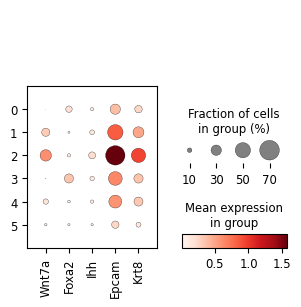

In [50]:
epi = full_un[full_un.obs["fine"].astype(str).str.contains("pitheli")].copy()
sc.pp.neighbors(epi); sc.tl.leiden(epi, resolution=0.5)
sc.pl.dotplot(epi, ["Wnt7a","Foxa2","Ihh","Epcam","Krt8"], groupby="leiden")
# LE = Wnt7a-high / Foxa2-low cluster;  GE = Foxa2-high.  Label the LE cluster back into full_un.obs["fine"].

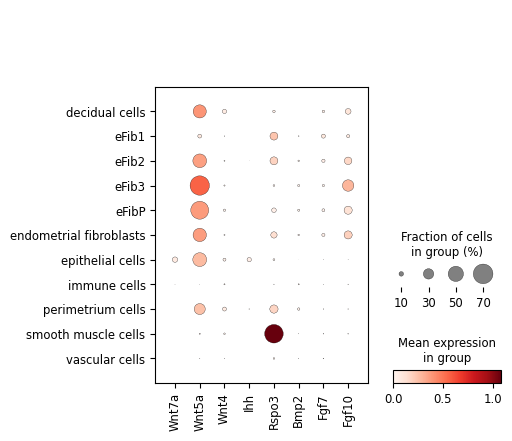

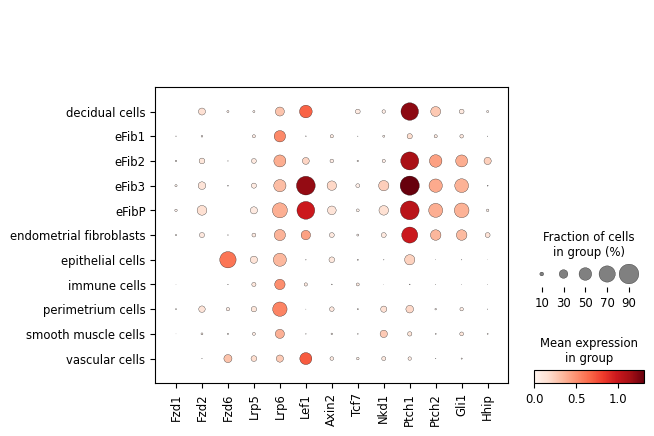

In [51]:
# SENDER (LE): does it make the ligands?  -> expect LE-high, ~absent in stroma
ligands = ["Wnt7a","Wnt5a","Wnt4","Ihh","Rspo3","Bmp2","Fgf7","Fgf10"]
sc.pl.dotplot(full_un, ligands, groupby="fine", layer="log1p", use_raw=False)

# RECEIVER (eFib3): receptors present AND the response elevated -> different genes than the ligands
receiver = ["Fzd1","Fzd2","Fzd6","Lrp5","Lrp6",     # Wnt7a receptor apparatus
            "Lef1","Axin2","Tcf7","Nkd1",            # de-confounded Wnt RESPONSE
            "Ptch1","Ptch2","Gli1","Hhip"]           # Ihh receptor + direct targets
sc.pl.dotplot(full_un, receiver, groupby="fine", layer="log1p", use_raw=False)

In [52]:
c = {"eFib1":"#639922","eFib2":"#378ADD","eFib3":"#E24B4A","eFibP":"#7F77DD","LE":"#111111"}
# scatter full_un by x_um_dbscan/y_um_dbscan colored by "fine", with LE in black on top

In [4]:
adata

AnnData object with n_obs × n_vars = 43052 × 33698
    obs: 'cell_barcode', 'cellbender_filtered', 'doubletdetection_doublet_score', 'doubletdetection_predicted_doublet', 'n_counts', 'n_genes_by_counts', 'pct_counts_in_top_20_genes', 'pct_counts_intronic', 'pct_counts_mito', 'pct_counts_ribo', 'timepoint', 'total_counts', 'total_counts_mito', 'total_counts_ribo', 'x_um', 'x_um_dbscan', 'y_um', 'y_um_dbscan', 'cell_type_annotations', 'cell_subtype_annotations', 'is_root', 'dpt_pseudotime', 'sample'
    var: 'mito', 'ribo', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches', 'mean', 'std'
    uns: 'diffmap_evals', 'hvg', 'iroot', 'log1p', 'neighbors', 'neighbors_scVI_100', 'rank_genes_groups', 'umap'
    obsm: 'X_dbscan_um', 'X_diffmap', 'X_pca', 'X_scVI', 'X_umap'
    varm: 'PCs'
    layers: 'log1p', 'raw'
    obsp: 'connectivities', 'distances', 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'

In [ ]:
import scanpy as sc

fib_un = adata[adata.obs["cell_subtype_annotations"].isin(["eFib1","eFib2","eFib3","eFibP"])].copy()



In [7]:
fib_un = fib_un[fib_un.obs['timepoint'] == 'uninduced'].copy()

In [8]:
fib_un.X = fib_un.layers["log1p"].copy()              # embed on log-normalized data
sc.pp.highly_variable_genes(fib_un, n_top_genes=2000) # HVGs on the fibs, not the full object
fib_un.raw = fib_un
fib_un = fib_un[:, fib_un.var.highly_variable].copy()
sc.pp.scale(fib_un, max_value=10)
sc.tl.pca(fib_un, n_comps=30)
sc.pp.neighbors(fib_un, n_neighbors=15, n_pcs=30)
sc.tl.umap(fib_un)

/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib64/python3.11/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: `n_top_genes` > number of normalized dispersions, returning all genes with normalized dispersions.
  return fn(*args_all, **kw)
/usr/lib64/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


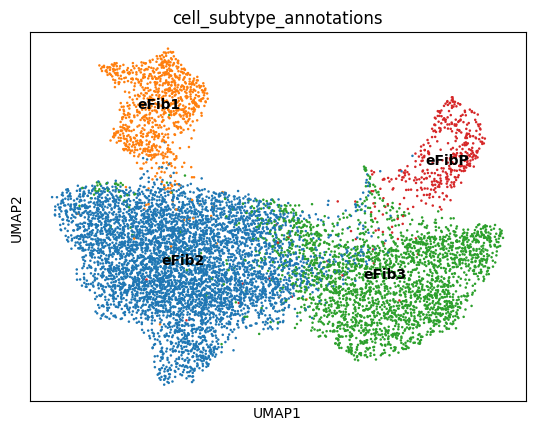

In [9]:
sc.pl.umap(fib_un, color="cell_subtype_annotations", legend_loc="on data")

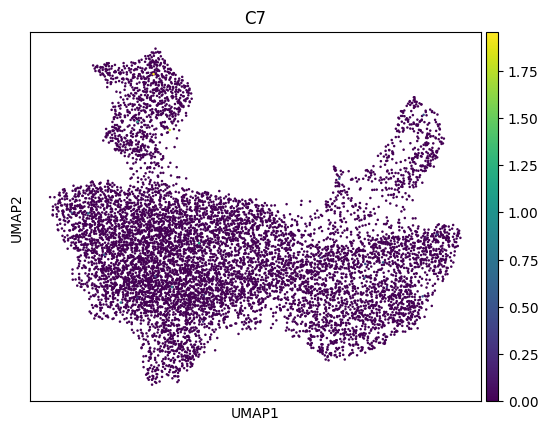

In [11]:
sc.pl.umap(fib_un, color=["C7"], layer = 'log1p')

                   S_score  G2M_score phase
CATACAGCACCTCTAC -0.830430   5.350591   G2M
TAATTCCCACAAGCCC  3.000000   3.523641   G2M
CCACACTCACCAGTTA -0.593271  -0.668637    G1
TACGCTCTCACCGACG -0.511183   1.276044   G2M
TCATCCGAGTTTCGAC  1.178575   1.867533   G2M


/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib64/python3.11/site-packages/scanpy/preprocessing/_simple.py:666: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib64/python3.11/site-packages/scanpy/preprocessing/_simple.py:666: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


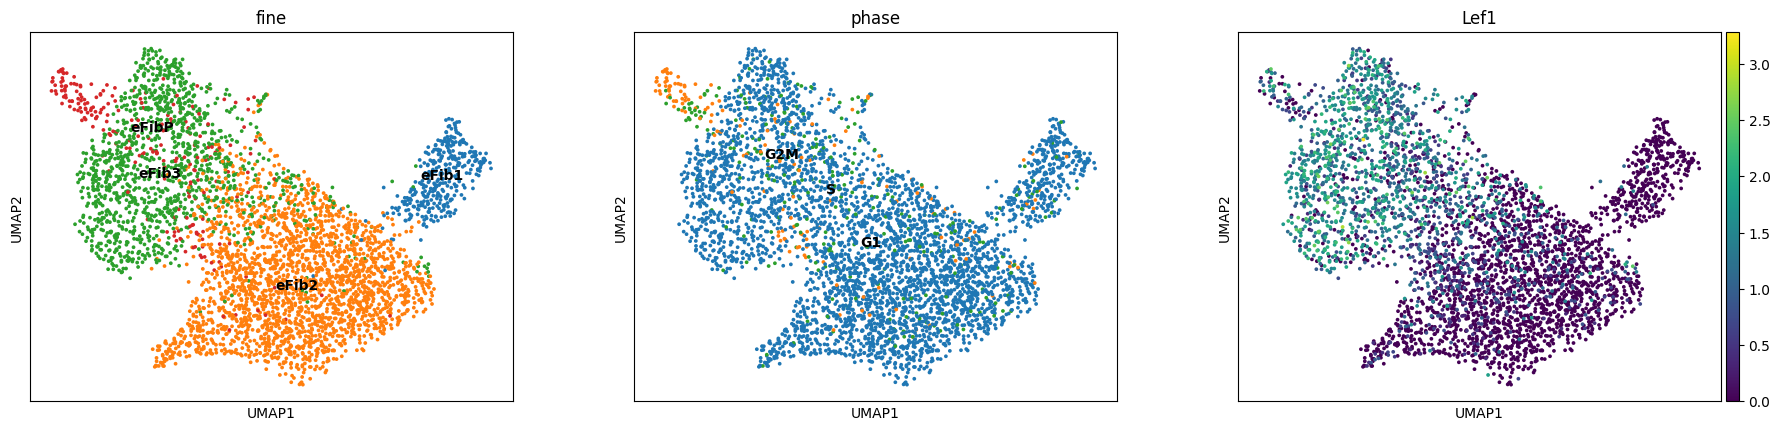

In [56]:
import scanpy as sc

fib_cc = full_un[full_un.obs["fine"].isin(["eFib1","eFib2","eFib3","eFibP"])].copy()
fib_cc.X = fib_cc.layers["log1p"].copy()

# --- score cell cycle HERE, on all genes, before HVG subsetting ---
s_genes = [g for g in s_genes_mouse   if g in fib_cc.var_names]   # your mouse lists from before
g2m     = [g for g in g2m_genes_mouse if g in fib_cc.var_names]
sc.tl.score_genes_cell_cycle(fib_cc, s_genes=s_genes, g2m_genes=g2m)   # writes S_score, G2M_score, phase
print(fib_cc.obs[["S_score","G2M_score","phase"]].head())

# --- now the rest, unchanged ---
sc.pp.highly_variable_genes(fib_cc, n_top_genes=2000)
fib_cc.raw = fib_cc
fib_cc = fib_cc[:, fib_cc.var.highly_variable].copy()
sc.pp.regress_out(fib_cc, ["S_score", "G2M_score"])
sc.pp.scale(fib_cc, max_value=10)
sc.tl.pca(fib_cc, n_comps=30)
sc.pp.neighbors(fib_cc, n_neighbors=15, n_pcs=30)
sc.tl.umap(fib_cc)
sc.pl.umap(fib_cc, color=["fine","phase","Lef1"], legend_loc="on data")

In [57]:
import scanpy as sc, numpy as np

# DE on the regressed values (fib_cc.X is post-regress_out, pre-scale-ideally;
# if you already scaled in place, re-run using .raw or a fresh regressed copy for interpretable logFCs)
sub = fib_cc[fib_cc.obs["fine"].isin(["eFib3","eFibP"])].copy()
sc.tl.rank_genes_groups(sub, "fine", groups=["eFibP"], reference="eFib3",
                        method="wilcoxon")
de = sc.get.rank_genes_groups_df(sub, group="eFibP")

# now FILTER OUT residual cell-cycle genes so they can't masquerade as the signal
cc = set(s_genes_mouse) | set(g2m_genes_mouse)
de_clean = de[~de["names"].isin(cc)]
print(de_clean.head(25))

       names     scores  logfoldchanges         pvals     pvals_adj
0     Diaph3  20.924582        7.089632  3.198547e-97  1.077846e-92
2      Cenpp  18.129229        4.235051  1.873685e-73  2.104648e-69
3      Kif15  17.895491        6.503967  1.278648e-71  1.077197e-67
4       Knl1  17.556562        8.420794  5.298844e-69  3.359606e-65
6       Nsd2  17.364134        2.829633  1.542084e-67  7.423593e-64
7     Cep128  17.268442        3.250325  8.130665e-67  3.424839e-63
9       Ezh2  17.061373        2.893369  2.877114e-65  9.695297e-62
10     Dleu2  17.041328        2.723700  4.054158e-65  1.241973e-61
12     Neil3  16.824760        9.014597  1.607128e-63  4.165924e-60
13    Zwilch  16.612200        4.033786  5.686934e-62  1.368845e-58
14    Mms22l  16.493761        3.580975  4.068136e-61  9.139203e-58
15     Lmnb1  16.385609        3.626542  2.423337e-60  5.103851e-57
16  Mis18bp1  16.215141        6.213682  3.941684e-59  7.813345e-56
20     Lockd  15.817735        8.332383  2.34787

In [58]:
import gseapy as gp
go = gp.get_library(name="GO_Biological_Process_2021", organism="Mouse")
cc = sorted({g for term, genes in go.items()
             if "cell cycle" in term.lower() or "mitot" in term.lower()
             for g in genes})
cc_broad = [g for g in cc if g in fib_cc.var_names]
print(f"{len(cc_broad)} cell-cycle genes matched")   # expect several hundred

0 cell-cycle genes matched


In [60]:
# expand the Tirosh core with the tiers that leaked, no network needed
extra = ["Knl1","Zwilch","Zwint","Ncapg","Ncapg2","Ncaph","Ncaph2","Ncapd2","Ncapd3",
         "Mis18bp1","Kntc1","Cenpe","Cenpf","Cenpk","Cenpp","Cenpa","Cenpu","Cenpn","Cenpo",
         "Kif4","Kif11","Kif15","Kif20a","Kif20b","Kif23","Kif2c","Kifc1",
         "Smc2","Smc4","Diaph3","Cit","Anln","Ect2","Racgap1","Sgo1","Sgo2a",
         "Bub1","Bub1b","Bub3","Ttk","Mad2l1","Aurka","Aurkb","Plk1","Plk4",
         "Ndc80","Nuf2","Spc24","Spc25","Ska1","Ska2","Ska3","Dsn1","Nsl1",
         "Neil3","Mms22l","Rad18","Rad51","Rad54l","Brca1","Brca2","Zgrf1","Exo1",
         "Lmnb1","Lockd","Dleu2","Ezh2","Nsd2","Top2a","Mki67","Ncapd2"]
cc_broad = sorted(set(s_genes_mouse) | set(g2m_genes_mouse) |
                  {g for g in extra if g in fib_cc.var_names})
cc_broad = [g for g in cc_broad if g in fib_cc.var_names]
print(f"{len(cc_broad)} cell-cycle genes")
sc.tl.score_genes(fib_cc, cc_broad, score_name="cc_score")
sc.pp.regress_out(fib_cc, ["cc_score"])

33 cell-cycle genes


In [61]:
print(list(fib_cc.var_names[:20]))     # symbols? Ensembl IDs? something else?
print(fib_cc.var.columns.tolist())     # is there a gene_symbol / feature_name column?
# is the failure specific genes or a format mismatch?
for g in ["Mki67","Top2a","Kif11","Bub1","Cenpe","Aurkb"]:
    print(g, g in fib_cc.var_names)

['Xkr4', 'Gm1992', 'Mybl1', 'Cpa6', 'Prex2', 'Sulf1', 'Slco5a1', 'Kcnb2', 'Gm28376', 'Pi15', 'Gm28154', 'Efhc1', 'Gsta3', 'Gm4956', 'Kcnq5', 'Adgrb3', 'Vwa3b', 'Npas2', 'Il1r1', 'Slc40a1']
['mito', 'ribo', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std']
Mki67 True
Top2a True
Kif11 True
Bub1 False
Cenpe True
Aurkb False


33 / 33 cc genes matched in full set


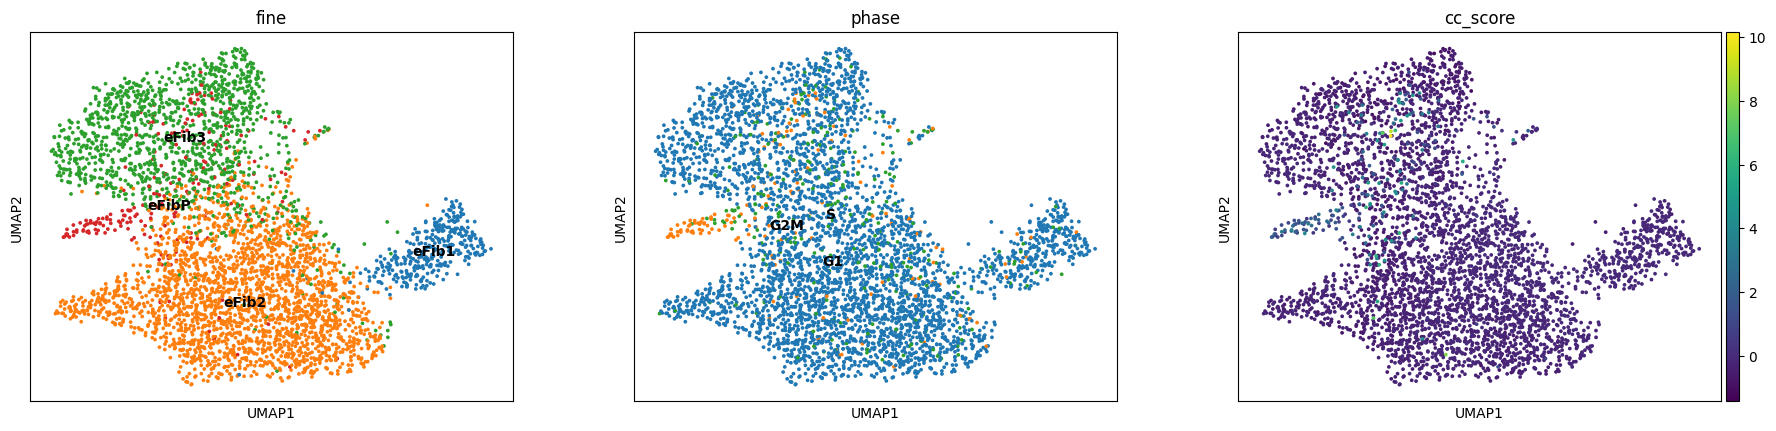

In [62]:
import scanpy as sc

# 1. score cc on ALL genes (before the HVG bottleneck)
fib_full = full_un[full_un.obs["fine"].isin(["eFib1","eFib2","eFib3","eFibP"])].copy()
fib_full.X = fib_full.layers["log1p"].copy()
cc_present = [g for g in cc_broad if g in fib_full.var_names]
print(f"{len(cc_present)} / {len(cc_broad)} cc genes matched in full set")   # now the big number

# smart: split S vs G2M so you can verify the score actually tracks cycling
sc.tl.score_genes(fib_full, cc_present, score_name="cc_score")

# 2. carry the score onto the HVG object and regress there
fib_cc.obs["cc_score"] = fib_full.obs["cc_score"].reindex(fib_cc.obs_names)
sc.pp.regress_out(fib_cc, ["cc_score"])
sc.pp.scale(fib_cc, max_value=10)
sc.tl.pca(fib_cc, n_comps=30); sc.pp.neighbors(fib_cc, n_pcs=30); sc.tl.umap(fib_cc)
sc.pl.umap(fib_cc, color=["fine","phase","cc_score"], legend_loc="on data")

KeyError: 'phase'

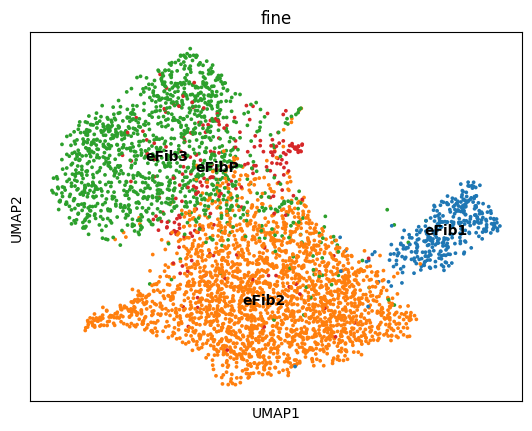

In [63]:
# recompute HVGs, then DROP any cell-cycle gene from the HVG set before PCA
sc.pp.highly_variable_genes(fib_full, n_top_genes=2000)
fib_full.var["highly_variable"] &= ~fib_full.var_names.isin(cc_present)   # exclude cc genes as features
fib_hvg = fib_full[:, fib_full.var.highly_variable].copy()
sc.tl.score_genes(fib_full, cc_present, score_name="cc_score")
fib_hvg.obs["cc_score"] = fib_full.obs["cc_score"]
sc.pp.regress_out(fib_hvg, ["cc_score"]); sc.pp.scale(fib_hvg, max_value=10)
sc.tl.pca(fib_hvg, n_comps=30); sc.pp.neighbors(fib_hvg, n_pcs=30); sc.tl.umap(fib_hvg)
sc.pl.umap(fib_hvg, color=["fine","phase"], legend_loc="on data")

In [64]:
import numpy as np, pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# use the cell-cycle-corrected PCA (identity space, cycle already stripped)
X = fib_hvg.obsm["X_pca"]
lab = fib_hvg.obs["fine"].values

# centroid of each territory, then cosine of eFibP's centroid to eFib2 vs eFib3
cent = {c: X[lab == c].mean(0) for c in ["eFib1","eFib2","eFib3","eFibP"]}
for c in ["eFib1","eFib2","eFib3"]:
    sim = cosine_similarity([cent["eFibP"]], [cent[c]])[0,0]
    print(f"eFibP vs {c}: cosine = {sim:.3f}")

eFibP vs eFib1: cosine = -0.521
eFibP vs eFib2: cosine = -0.417
eFibP vs eFib3: cosine = 0.689


In [65]:
# for each eFibP cell, cosine to each territory centroid; assign to the closest
P = X[lab == "eFibP"]
sims = {c: cosine_similarity(P, [cent[c]])[:,0] for c in ["eFib1","eFib2","eFib3"]}
assign = pd.DataFrame(sims).idxmax(1)
print(assign.value_counts(normalize=True))          # the eFib3-vs-eFib2 split, per cell
print(pd.DataFrame(sims).mean())                     # mean similarity per territory

eFib3    0.747706
eFib2    0.238532
eFib1    0.013761
Name: proportion, dtype: float64
eFib1   -0.216950
eFib2   -0.155711
eFib3    0.273144
dtype: float32


/usr/lib64/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


KeyError: 'Could not find key Lef1 in .var_names or .obs.columns.'

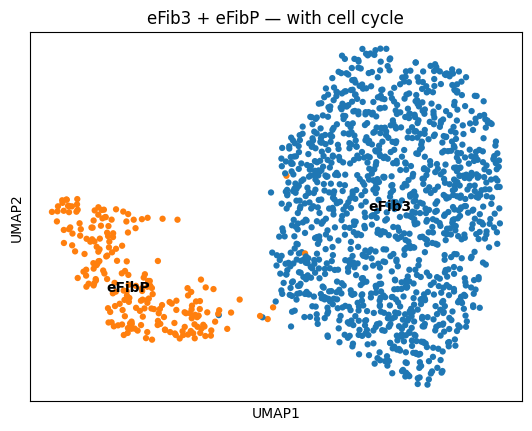

In [67]:
import scanpy as sc

# ---- cell-cycle gene sets --------------------------------------------------
# Tirosh core (from earlier) + the kinetochore/spindle/condensin/checkpoint/repair
# tiers that leaked into the DE. Scored on the FULL gene set, not the HVG subset.
extra_cc = ["Knl1","Zwilch","Zwint","Ncapg","Ncapg2","Ncaph","Ncaph2","Ncapd2","Ncapd3",
    "Mis18bp1","Kntc1","Cenpe","Cenpf","Cenpk","Cenpp","Cenpa","Cenpu","Cenpn","Cenpo",
    "Kif4","Kif11","Kif15","Kif20a","Kif20b","Kif23","Kif2c","Kifc1","Smc2","Smc4",
    "Diaph3","Cit","Anln","Ect2","Racgap1","Sgo1","Sgo2a","Bub1","Bub1b","Bub3","Ttk",
    "Mad2l1","Aurka","Aurkb","Plk1","Plk4","Ndc80","Nuf2","Spc24","Spc25","Ska1","Ska2",
    "Ska3","Dsn1","Nsl1","Neil3","Mms22l","Rad18","Rad51","Rad54l","Brca1","Brca2",
    "Zgrf1","Exo1","Lmnb1","Lockd","Dleu2","Ezh2","Nsd2","Top2a","Mki67"]
cc_all = sorted(set(s_genes_mouse) | set(g2m_genes_mouse) | set(extra_cc))

# ---- embedding helper ------------------------------------------------------
def embed(ad, regress):
    a = ad.copy()
    a.X = a.layers["log1p"].copy()
    cc = [g for g in cc_all if g in a.var_names]          # match on FULL gene set
    sc.tl.score_genes(a, cc, score_name="cc_score")       # one broad cc score
    sc.pp.highly_variable_genes(a, n_top_genes=2000)
    if regress:
        a.var["highly_variable"] &= ~a.var_names.isin(cc) # drop cc genes from features too
    a = a[:, a.var.highly_variable].copy()
    if regress:
        sc.pp.regress_out(a, ["cc_score"])
    sc.pp.scale(a, max_value=10)
    sc.tl.pca(a, n_comps=30)
    sc.pp.neighbors(a, n_neighbors=15, n_pcs=30)
    sc.tl.umap(a)
    return a

# ---- run on eFib3 + eFibP only --------------------------------------------
pair = full_un[full_un.obs["fine"].isin(["eFib3","eFibP"])].copy()
a_with = embed(pair, regress=False)   # cell cycle KEPT  -> splits (expected, uninformative)
a_wo   = embed(pair, regress=True)    # cell cycle GONE  -> the informative panel

# ---- plot (no `phase`, use_raw=False avoids the .raw KeyError) --------------
sc.pl.umap(a_with, color=["fine","Lef1"], use_raw=False,
           legend_loc="on data", title="eFib3 + eFibP — with cell cycle")
sc.pl.umap(a_wo,   color=["fine","Lef1"], use_raw=False,
           legend_loc="on data", title="eFib3 + eFibP — cell cycle regressed")

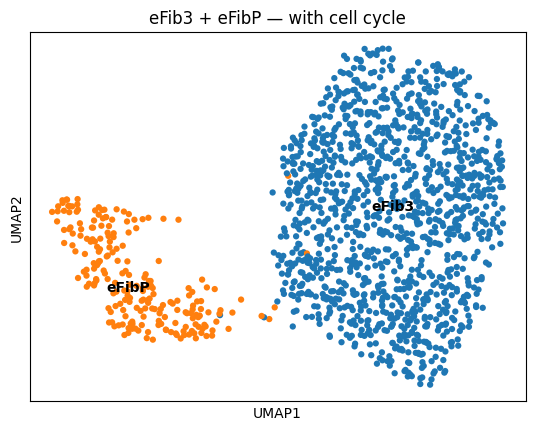

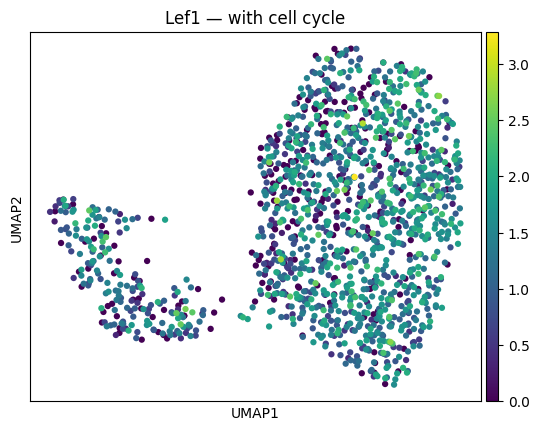

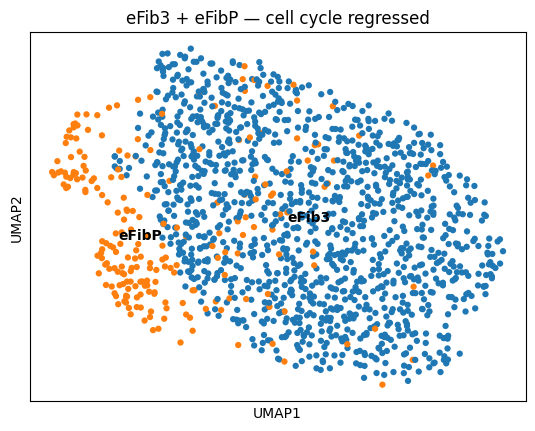

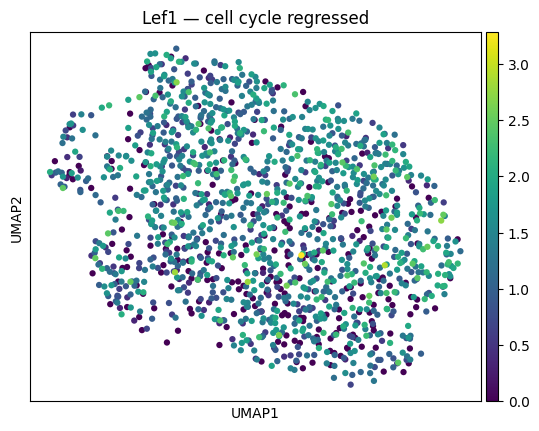

In [71]:
for a, ttl in [(a_with, "with cell cycle"), (a_wo, "cell cycle regressed")]:
    sc.pl.umap(a, color="fine", legend_loc="on data", title=f"eFib3 + eFibP — {ttl}")
    sc.pl.umap(a, color="Lef1", use_raw=False, layer = 'log1p', title=f"Lef1 — {ttl}")   # Lef1 read from .raw (full genes)

/usr/lib64/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


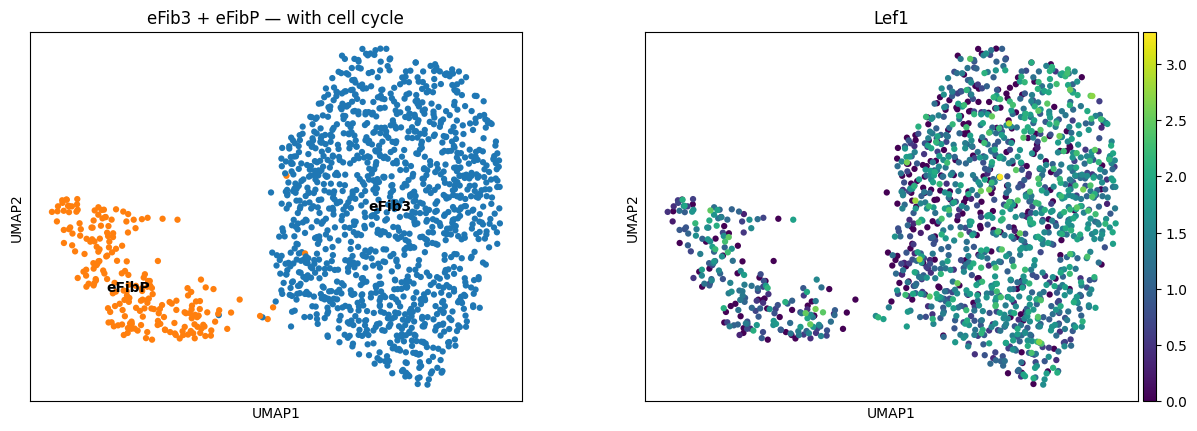

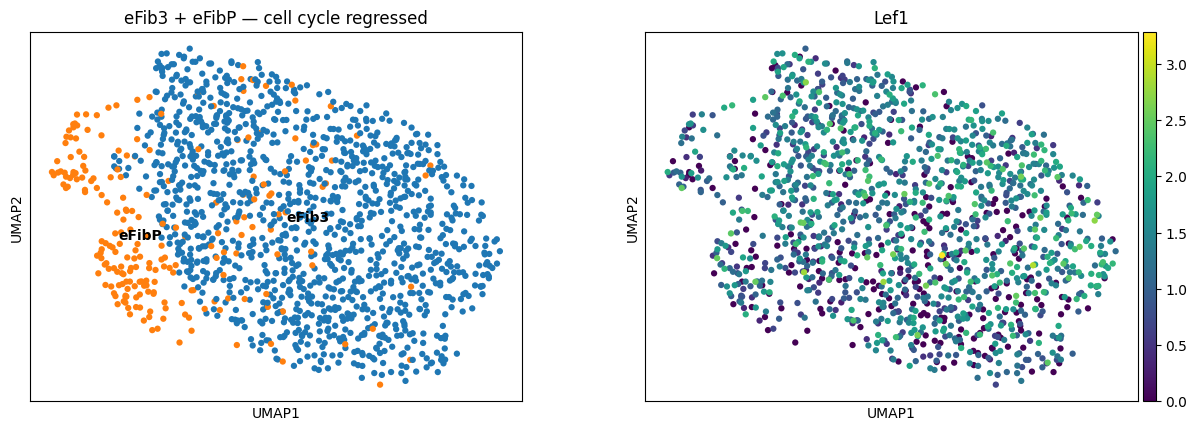

In [69]:
def embed(ad, regress, keep_genes=("Lef1","Gli1","Mki67")):
    a = ad.copy()
    a.X = a.layers["log1p"].copy()
    for g in keep_genes:                                   # park genes in .obs so HVG subsetting can't drop them
        if g in a.var_names:
            a.obs[g] = a[:, g].X.toarray().ravel() if hasattr(a[:, g].X, "toarray") else a[:, g].X.ravel()
    cc = [g for g in cc_all if g in a.var_names]
    sc.tl.score_genes(a, cc, score_name="cc_score")
    sc.pp.highly_variable_genes(a, n_top_genes=2000)
    if regress:
        a.var["highly_variable"] &= ~a.var_names.isin(cc)
    a = a[:, a.var.highly_variable].copy()
    if regress:
        sc.pp.regress_out(a, ["cc_score"])
    sc.pp.scale(a, max_value=10)
    sc.tl.pca(a, n_comps=30); sc.pp.neighbors(a, n_neighbors=15, n_pcs=30); sc.tl.umap(a)
    return a

pair = full_un[full_un.obs["fine"].isin(["eFib3","eFibP"])].copy()
a_with = embed(pair, regress=False)
a_wo   = embed(pair, regress=True)

for a, ttl in [(a_with,"with cell cycle"), (a_wo,"cell cycle regressed")]:
    sc.pl.umap(a, color=["fine","Lef1"], legend_loc="on data",   # Lef1 now lives in .obs, always plottable
               title=f"eFib3 + eFibP — {ttl}")

ValueError: Key Sema5a could be found in both .var_names and .obs.columns

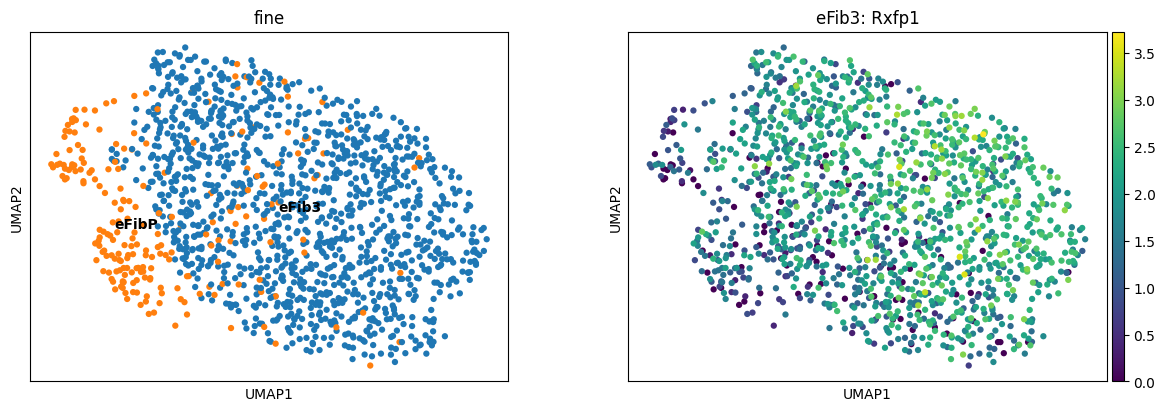

In [74]:
import numpy as np, pandas as pd, scanpy as sc

efib3_markers = ["Rxfp1","Sema5a","Prickle2","Cntn3","Tmem132c","Piezo2"]
efib2_markers = ["Kcnd2","Nlgn1","Ebf1","Igf1","Sned1","Naaladl2"]
panel = efib3_markers + efib2_markers

# pull these genes from the full-gene parent and attach by barcode (survives HVG subsetting)
src = full_un.copy(); src.X = src.layers["log1p"].copy()
for g in panel:
    if g in src.var_names:
        v = src[:, g].X
        v = v.toarray().ravel() if hasattr(v, "toarray") else np.asarray(v).ravel()
        ser = pd.Series(v, index=src.obs_names)
        a_wo.obs[g]   = ser.reindex(a_wo.obs_names).values
        a_with.obs[g] = ser.reindex(a_with.obs_names).values

# feature overlays on the REGRESSED eFib3+eFibP embedding (the informative one)
sc.pl.umap(a_wo, color=["fine"] + efib3_markers, legend_loc="on data",
           title=["fine"] + [f"eFib3: {g}" for g in efib3_markers], ncols=4)
sc.pl.umap(a_wo, color=["fine"] + efib2_markers, legend_loc="on data",
           title=["fine"] + [f"eFib2: {g}" for g in efib2_markers], ncols=4)

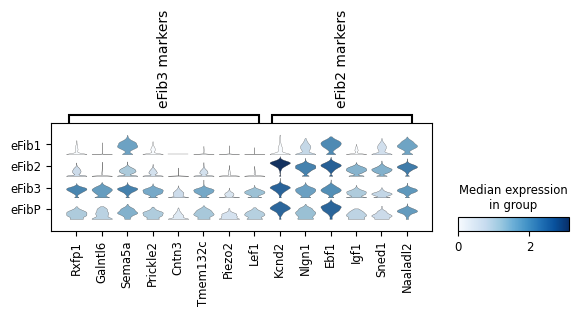

In [75]:
import scanpy as sc

efib3_markers = ["Rxfp1","Galntl6","Sema5a","Prickle2","Cntn3","Tmem132c","Piezo2","Lef1"]
efib2_markers = ["Kcnd2","Nlgn1","Ebf1","Igf1","Sned1","Naaladl2"]

fibs = full_un[full_un.obs["fine"].isin(["eFib1","eFib2","eFib3","eFibP"])].copy()
fibs.obs["fine"] = fibs.obs["fine"].cat.reorder_categories(["eFib1","eFib2","eFib3","eFibP"])

# stacked violins — compact, all markers at once, grouped by territory
sc.pl.stacked_violin(
    fibs,
    {"eFib3 markers": [g for g in efib3_markers if g in fibs.var_names],
     "eFib2 markers": [g for g in efib2_markers if g in fibs.var_names]},
    groupby="fine", layer="log1p", use_raw=False, swap_axes=False, dendrogram=False)

Wnt7a: 634 cells expressing / 16841  (3.8%)


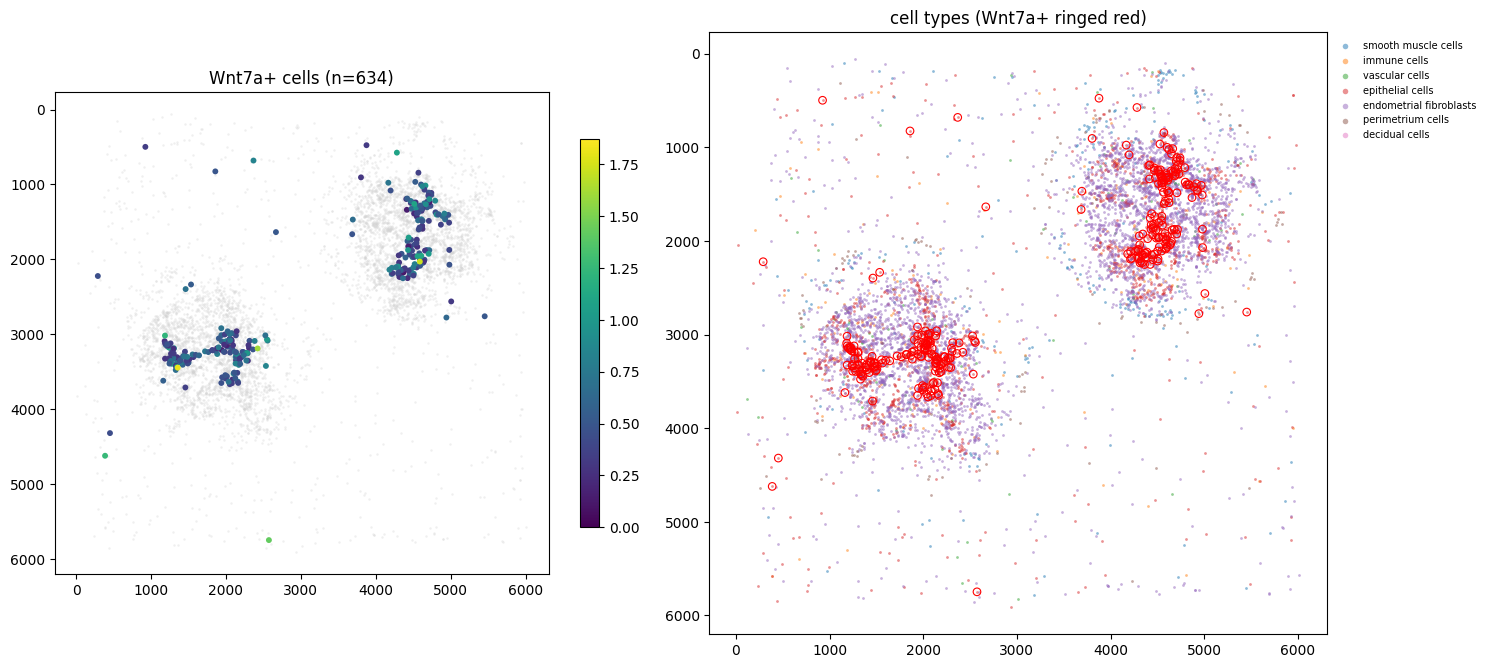

In [77]:
import numpy as np, scanpy as sc, matplotlib.pyplot as plt

# uninduced, full object (all cell types — we WANT epithelium here, not just fibs)
fu = full[full.obs["timepoint"] == "uninduced"].copy()
x, y = fu.obs["x_um_dbscan"], fu.obs["y_um_dbscan"]

# Wnt7a expression, from log1p, as a per-cell vector
g = "Wnt7a"
v = fu[:, g].layers["log1p"] if "log1p" in fu.layers else fu[:, g].X
v = np.asarray(v.todense()).ravel() if hasattr(v, "todense") else np.asarray(v).ravel()
print(f"{g}: {(v>0).sum()} cells expressing / {len(v)}  ({(v>0).mean():.1%})")   # <- read this first

fig, ax = plt.subplots(1, 2, figsize=(15, 7))

# left: grey all cells, then plot ONLY Wnt7a+ cells on top, sized/colored by level
ax[0].scatter(x, y, s=3, c="lightgrey", alpha=.35, linewidths=0)
pos = v > 0
sca = ax[0].scatter(x[pos], y[pos], s=18, c=v[pos], cmap="viridis", linewidths=0, vmin=0)
ax[0].set_title(f"{g}+ cells (n={pos.sum()})"); ax[0].set_aspect("equal"); ax[0].invert_yaxis()
plt.colorbar(sca, ax=ax[0], shrink=.6)

# right: same coords colored by cell type, so you can see WHERE the Wnt7a+ cells sit
ct = fu.obs["fine"].astype(str) if "fine" in fu.obs else fu.obs["cell_type_annotations"].astype(str)
for c in ct.unique():
    m = (ct == c).values
    ax[1].scatter(x[m], y[m], s=4, alpha=.5, label=c, linewidths=0)
ax[1].scatter(x[pos], y[pos], s=30, facecolors="none", edgecolors="red", linewidths=0.8)  # ring the Wnt7a+ cells
ax[1].set_title("cell types (Wnt7a+ ringed red)"); ax[1].set_aspect("equal"); ax[1].invert_yaxis()
ax[1].legend(markerscale=2, fontsize=7, frameon=False, bbox_to_anchor=(1,1))
plt.tight_layout(); plt.show()

Ihh: 476 cells expressing / 16841  (2.8%)


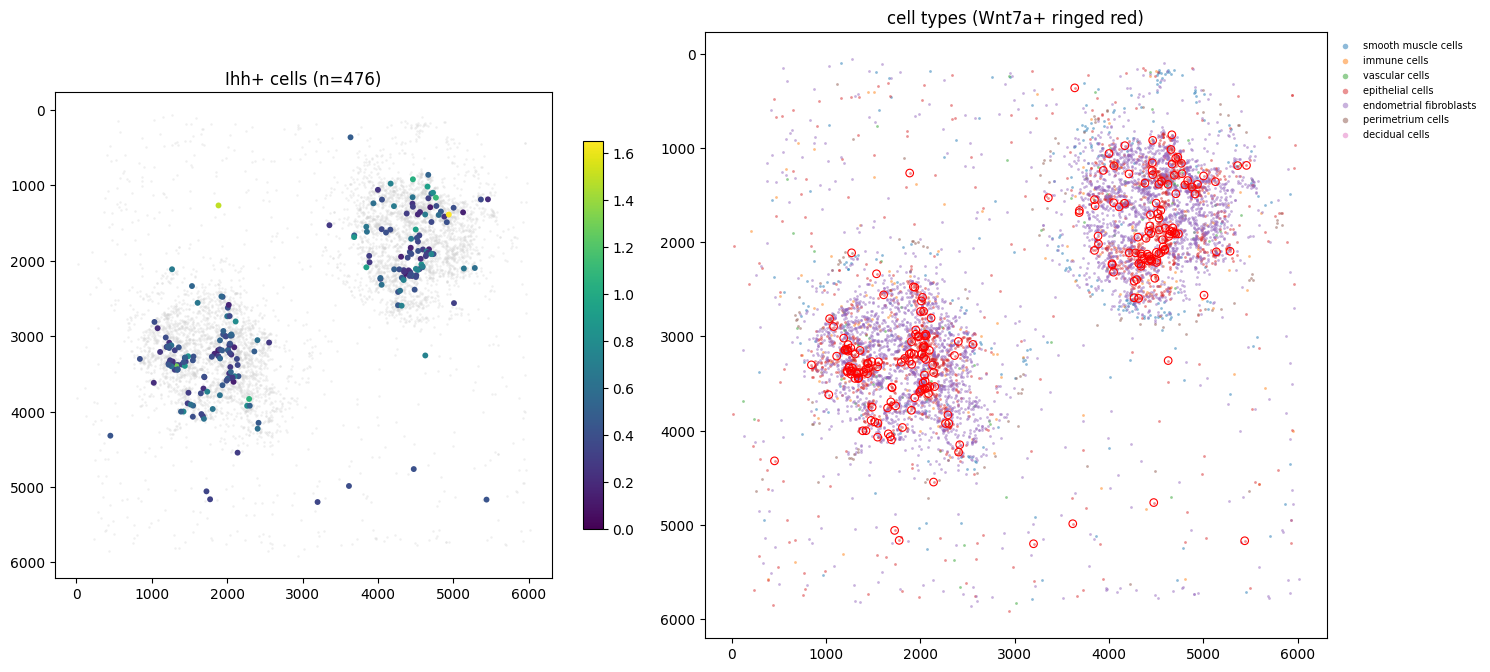

In [78]:
import numpy as np, scanpy as sc, matplotlib.pyplot as plt

# uninduced, full object (all cell types — we WANT epithelium here, not just fibs)
fu = full[full.obs["timepoint"] == "uninduced"].copy()
x, y = fu.obs["x_um_dbscan"], fu.obs["y_um_dbscan"]

# Wnt7a expression, from log1p, as a per-cell vector
g = "Ihh"
v = fu[:, g].layers["log1p"] if "log1p" in fu.layers else fu[:, g].X
v = np.asarray(v.todense()).ravel() if hasattr(v, "todense") else np.asarray(v).ravel()
print(f"{g}: {(v>0).sum()} cells expressing / {len(v)}  ({(v>0).mean():.1%})")   # <- read this first

fig, ax = plt.subplots(1, 2, figsize=(15, 7))

# left: grey all cells, then plot ONLY Wnt7a+ cells on top, sized/colored by level
ax[0].scatter(x, y, s=3, c="lightgrey", alpha=.35, linewidths=0)
pos = v > 0
sca = ax[0].scatter(x[pos], y[pos], s=18, c=v[pos], cmap="viridis", linewidths=0, vmin=0)
ax[0].set_title(f"{g}+ cells (n={pos.sum()})"); ax[0].set_aspect("equal"); ax[0].invert_yaxis()
plt.colorbar(sca, ax=ax[0], shrink=.6)

# right: same coords colored by cell type, so you can see WHERE the Wnt7a+ cells sit
ct = fu.obs["fine"].astype(str) if "fine" in fu.obs else fu.obs["cell_type_annotations"].astype(str)
for c in ct.unique():
    m = (ct == c).values
    ax[1].scatter(x[m], y[m], s=4, alpha=.5, label=c, linewidths=0)
ax[1].scatter(x[pos], y[pos], s=30, facecolors="none", edgecolors="red", linewidths=0.8)  # ring the Wnt7a+ cells
ax[1].set_title("cell types (Wnt7a+ ringed red)"); ax[1].set_aspect("equal"); ax[1].invert_yaxis()
ax[1].legend(markerscale=2, fontsize=7, frameon=False, bbox_to_anchor=(1,1))
plt.tight_layout(); plt.show()

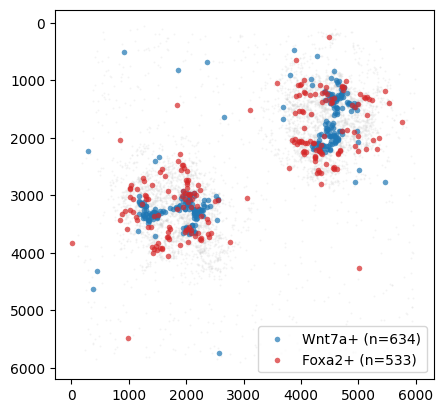

In [79]:
# same coords, Wnt7a+ vs Foxa2+ overlaid — does the structure carry the luminal or glandular marker?
for g, col in [("Wnt7a","#1f77b4"), ("Foxa2","#d62728")]:
    v = fu[:, g].layers["log1p"] if "log1p" in fu.layers else fu[:, g].X
    v = np.asarray(v.todense()).ravel() if hasattr(v,"todense") else np.asarray(v).ravel()
    m = v > 0
    plt.scatter(x[m], y[m], s=16, c=col, alpha=.7, linewidths=0, label=f"{g}+ (n={m.sum()})")
plt.scatter(x, y, s=2, c="lightgrey", alpha=.25, linewidths=0, zorder=-1)
plt.gca().set_aspect("equal"); plt.gca().invert_yaxis(); plt.legend(); plt.show()

In [83]:
import numpy as np, pandas as pd
from scipy.stats import spearmanr

def vec(ad, g):
    v = ad[:, g].layers["log1p"] if "log1p" in ad.layers else ad[:, g].X
    return np.asarray(v.todense()).ravel() if hasattr(v, "todense") else np.asarray(v).ravel()

fo, ih = vec(fu, "Foxa2"), vec(fu, "Ihh")
print(f"Foxa2+: {(fo>0).mean():.1%}   Ihh+: {(ih>0).mean():.1%}   both+: {((fo>0)&(ih>0)).mean():.1%}")

# 1. across ALL cells — will be inflated by shared zeros (mostly tells you 'both epithelial')
print("all cells:        ", spearmanr(fo, ih))

# 2. WITHIN epithelium only — the meaningful test: does Foxa2 track Ihh among epithelial cells?
epi = fu.obs["fine"].astype(str).str.contains("pitheli") if "fine" in fu.obs \
      else fu.obs["cell_type_annotations"].astype(str).str.contains("pitheli")
epi = epi.values
print(f"epithelial cells: n={epi.sum()}")
print("within epithelium:", spearmanr(fo[epi], ih[epi]))

# 3. and the cleanest: is Ihh enriched specifically in Foxa2+ epithelium vs Foxa2- epithelium?
from scipy.stats import mannwhitneyu
fo_pos = epi & (fo > 0)
fo_neg = epi & (fo == 0)
print("Ihh in Foxa2+ vs Foxa2- epi:", mannwhitneyu(ih[fo_pos], ih[fo_neg], alternative="greater"))

Foxa2+: 3.2%   Ihh+: 2.8%   both+: 0.4%
all cells:         SignificanceResult(statistic=np.float64(0.09004293521257062), pvalue=np.float64(1.159128737766064e-31))
epithelial cells: n=5052
within epithelium: SignificanceResult(statistic=np.float64(0.01626591879208307), pvalue=np.float64(0.24770980792005612))
Ihh in Foxa2+ vs Foxa2- epi: MannwhitneyuResult(statistic=np.float64(1222826.0), pvalue=np.float64(0.08071136687915437))


In [90]:
# what IS eFib2i — a timepoint-specific state, or a co-occurring territory?
import pandas as pd
print(pd.crosstab(adata.obs["cell_subtype_annotations"], adata.obs["timepoint"]))
# if eFib2i is ~absent in uninduced and appears on induction -> it's a STATE (decidual-adjacent), not a spatial sibling

timepoint                 1_dpi_early  1_dpi_late  2_dpi  3_dpi  \
cell_subtype_annotations                                          
decAp                               2         161     68     39   
dec1                              380        1843    585   2036   
dec2                              768        3296   1372   4859   
dec3                                0         404    346   1887   
eFib2                              41         128     34     26   
eFib2i                            830        3508    921   1488   
eFib1                              79         393    166    324   
eFib3                             285         689     11     16   
eFibP                             222         300     36     48   

timepoint                 4_dpi_bleeding  uninduced  
cell_subtype_annotations                             
decAp                                727          0  
dec1                                 367         16  
dec2                                2790      

In [91]:
# both populations present in the SAME sample -> difference is state, not timepoint
tp = adata[adata.obs["timepoint"].isin(["1_dpi_early","1_dpi_late"])]
sub2 = tp[tp.obs["cell_subtype_annotations"].isin(["eFib2","eFib2i"])].copy()
print(sub2.obs.groupby(["timepoint","cell_subtype_annotations"]).size())  # confirm both present per tp
sc.tl.rank_genes_groups(sub2, "cell_subtype_annotations", groups=["eFib2i"],
                        reference="eFib2", method="wilcoxon", layer="log1p", use_raw=False)
print(sc.get.rank_genes_groups_df(sub2, group="eFib2i").head(30))

/tmp/ipykernel_593680/2850915683.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(sub2.obs.groupby(["timepoint","cell_subtype_annotations"]).size())  # confirm both present per tp


timepoint    cell_subtype_annotations
1_dpi_early  eFib2                         41
             eFib2i                       830
1_dpi_late   eFib2                        128
             eFib2i                      3508
dtype: int64
      names    scores  logfoldchanges     pvals  pvals_adj
0    Prune2  4.826017        1.379128  0.000001   0.023469
1      Ror2  4.623733        0.726715  0.000004   0.030427
2     Tenm3  4.586162        0.582833  0.000005   0.030427
3    Col1a2  4.497493        0.592081  0.000007   0.038618
4    Malat1  4.433771        0.241216  0.000009   0.044577
5    Tgfbr2  4.093799        0.690884  0.000042   0.143002
6      Tcf4  4.037519        0.340478  0.000054   0.161840
7     Nrxn3  4.022304        1.353396  0.000058   0.161840
8    Col6a3  3.966686        0.940664  0.000073   0.164385
9    Fndc3b  3.940142        0.528184  0.000081   0.164385
10  Col11a1  3.935774        1.308679  0.000083   0.164385
11  Slco5a1  3.921583        1.006623  0.000088   0.16468

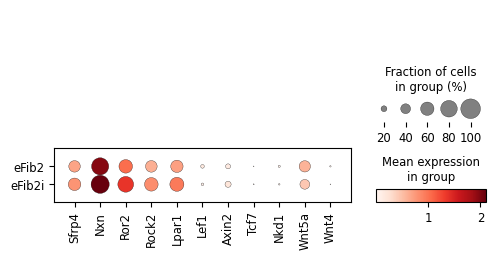

In [92]:
import scanpy as sc
tp = adata[adata.obs["timepoint"].isin(["1_dpi_early","1_dpi_late"])]
sub2 = tp[tp.obs["cell_subtype_annotations"].isin(["eFib2","eFib2i"])].copy()

# where does Sfrp4 (and the canonical-brake set) actually sit, within-timepoint?
sc.pl.dotplot(sub2, ["Sfrp4","Nxn","Ror2","Rock2","Lpar1",     # the two Wnt arms
                     "Lef1","Axin2","Tcf7","Nkd1",             # canonical RESPONSE — should be LOWER in eFib2i if the story holds
                     "Wnt5a","Wnt4"],                          # ligands: is the non-canonical ligand (Wnt5a) or decidual Wnt (Wnt4) present?
              groupby="cell_subtype_annotations", layer="log1p", use_raw=False)

In [96]:
adata.obs.columns

Index(['cell_barcode', 'cellbender_filtered', 'doubletdetection_doublet_score',
       'doubletdetection_predicted_doublet', 'n_counts', 'n_genes_by_counts',
       'pct_counts_in_top_20_genes', 'pct_counts_intronic', 'pct_counts_mito',
       'pct_counts_ribo', 'timepoint', 'total_counts', 'total_counts_mito',
       'total_counts_ribo', 'x_um', 'x_um_dbscan', 'y_um', 'y_um_dbscan',
       'cell_type_annotations', 'cell_subtype_annotations', 'is_root',
       'dpt_pseudotime', 'sample'],
      dtype='object')

In [97]:
fd = adata.copy()

C7 in var_names: True


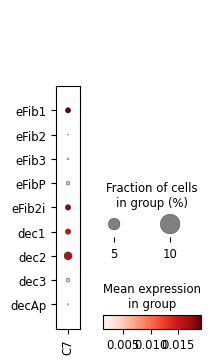

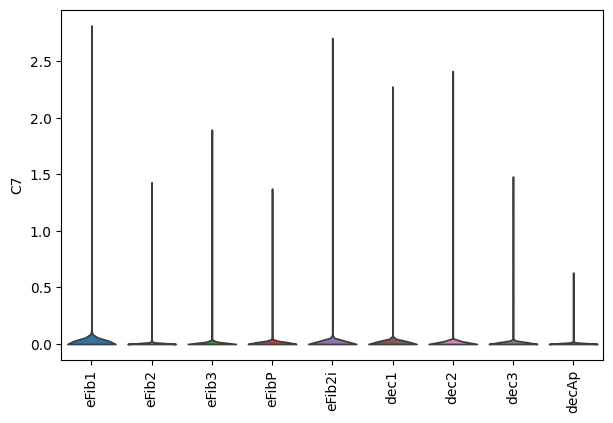

In [100]:
import scanpy as sc

groups = ["eFib1","eFib2","eFib3","eFibP","eFib2i","dec1","dec2","dec3","decAp"]
fd = adata[adata.obs["cell_subtype_annotations"].isin(groups)].copy()
fd.obs["cell_subtype_annotations"] = fd.obs["cell_subtype_annotations"].cat.reorder_categories([g for g in groups if g in fd.obs["cell_subtype_annotations"].unique()])

print("C7 in var_names:", "C7" in fd.var_names)   # sanity check it's captured at all

# fraction expressing + mean per group — the direct "who expresses it"
sc.pl.dotplot(fd, ["C7"], groupby="cell_subtype_annotations", layer="log1p", use_raw=False)

# distribution, in case it's a subset within a group rather than uniform
sc.pl.violin(fd, "C7", groupby="cell_subtype_annotations", layer="log1p", use_raw=False, rotation=90, stripplot=False)

33 / 33 cc genes matched in full set


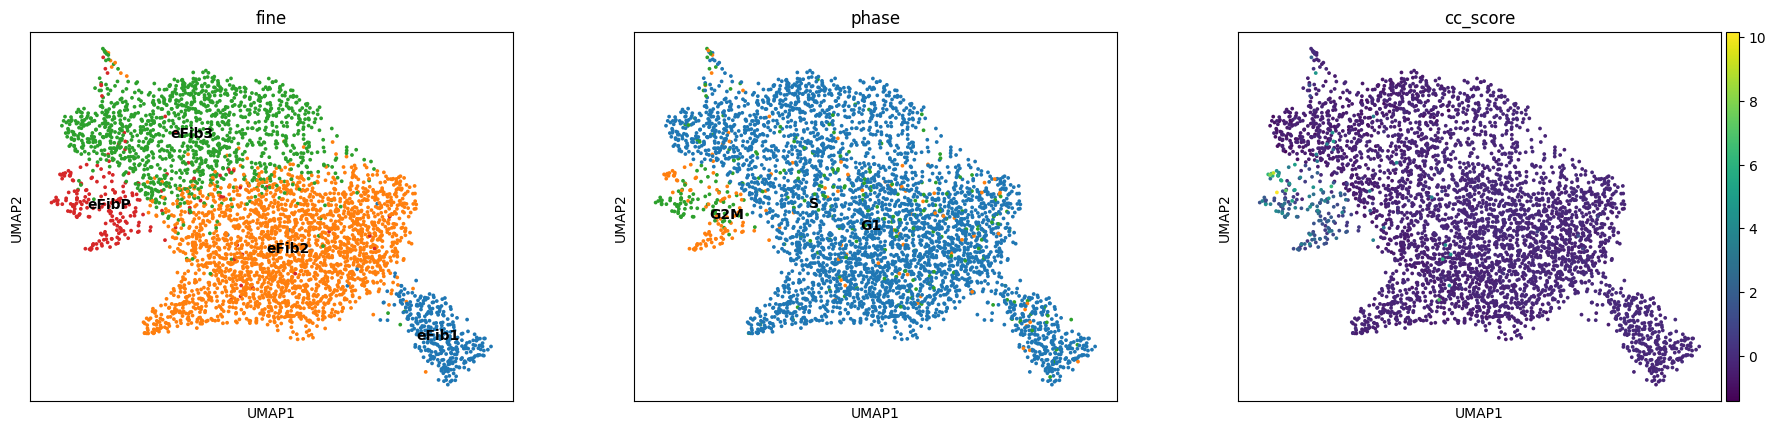

In [101]:
import scanpy as sc

# 1. score cc on ALL genes (before the HVG bottleneck)
fib_full = full_un[full_un.obs["fine"].isin(["eFib1","eFib2","eFib3","eFibP"])].copy()
fib_full.X = fib_full.layers["log1p"].copy()
cc_present = [g for g in cc_broad if g in fib_full.var_names]
print(f"{len(cc_present)} / {len(cc_broad)} cc genes matched in full set")   # now the big number

# smart: split S vs G2M so you can verify the score actually tracks cycling
sc.tl.score_genes(fib_full, cc_present, score_name="cc_score")

# 2. carry the score onto the HVG object and regress there
fib_cc.obs["cc_score"] = fib_full.obs["cc_score"].reindex(fib_cc.obs_names)
sc.pp.regress_out(fib_cc, ["cc_score"])
sc.pp.scale(fib_cc, max_value=10)
sc.tl.pca(fib_cc, n_comps=30); sc.pp.neighbors(fib_cc, n_pcs=30); sc.tl.umap(fib_cc)
sc.pl.umap(fib_cc, color=["fine","phase","cc_score"], legend_loc="on data")

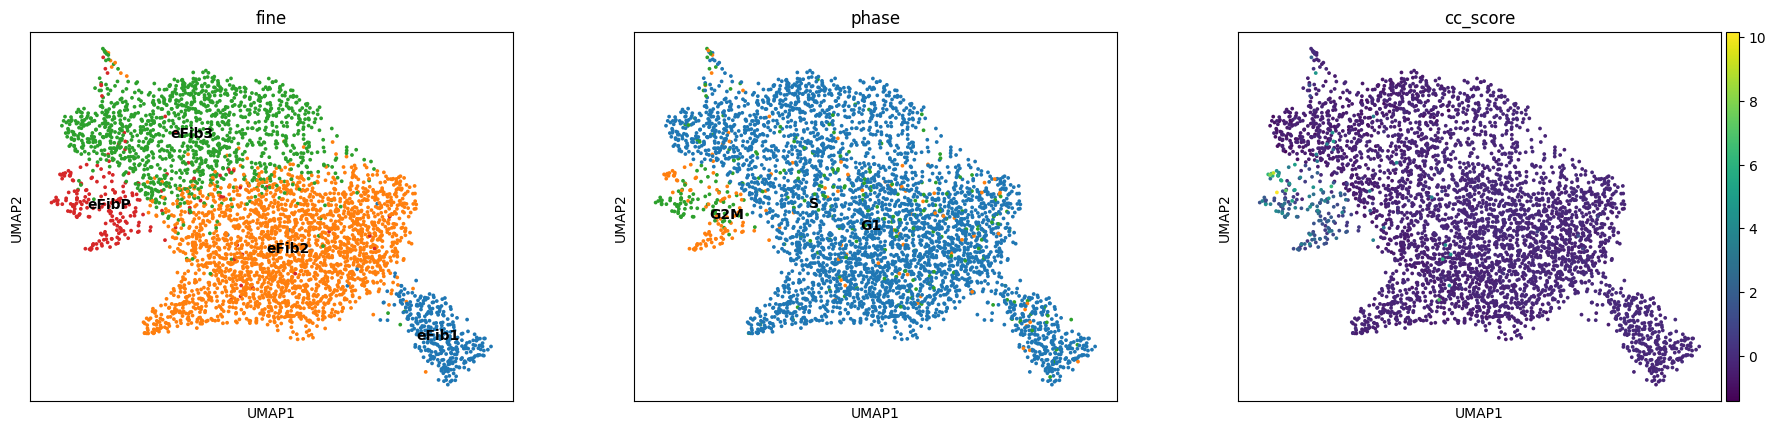

In [102]:
sc.pl.umap(fib_cc, color=["fine","phase","cc_score"], legend_loc="on data")

In [104]:
fib_cc

AnnData object with n_obs × n_vars = 4091 × 2000
    obs: 'cell_barcode', 'cellbender_filtered', 'doubletdetection_doublet_score', 'doubletdetection_predicted_doublet', 'n_counts', 'n_genes_by_counts', 'pct_counts_in_top_20_genes', 'pct_counts_intronic', 'pct_counts_mito', 'pct_counts_ribo', 'sample', 'timepoint', 'total_counts', 'total_counts_mito', 'total_counts_ribo', 'x_um', 'x_um_dbscan', 'y_um', 'y_um_dbscan', 'cell_type_annotations', 'fine', 'S_score', 'G2M_score', 'phase', 'cc_score'
    var: 'mito', 'ribo', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'neighbors_scVI_100', 'rank_genes_groups', 'umap', 'pca', 'neighbors', 'fine_colors', 'phase_colors'
    obsm: 'X_scVI', 'X_umap', 'X_pca'
    varm: 'PCs'
    layers: 'log1p', 'raw'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances', 'distances', 'connectivities'

KeyError: 'Could not find key Axin2 in .var_names or .obs.columns.'

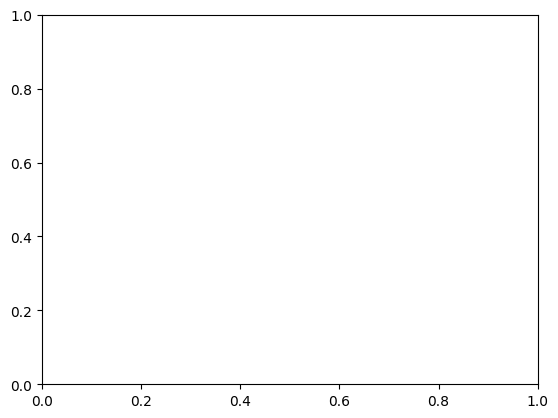

In [103]:
sc.pl.umap(fib_cc, color='Axin2', layer = 'log1p')

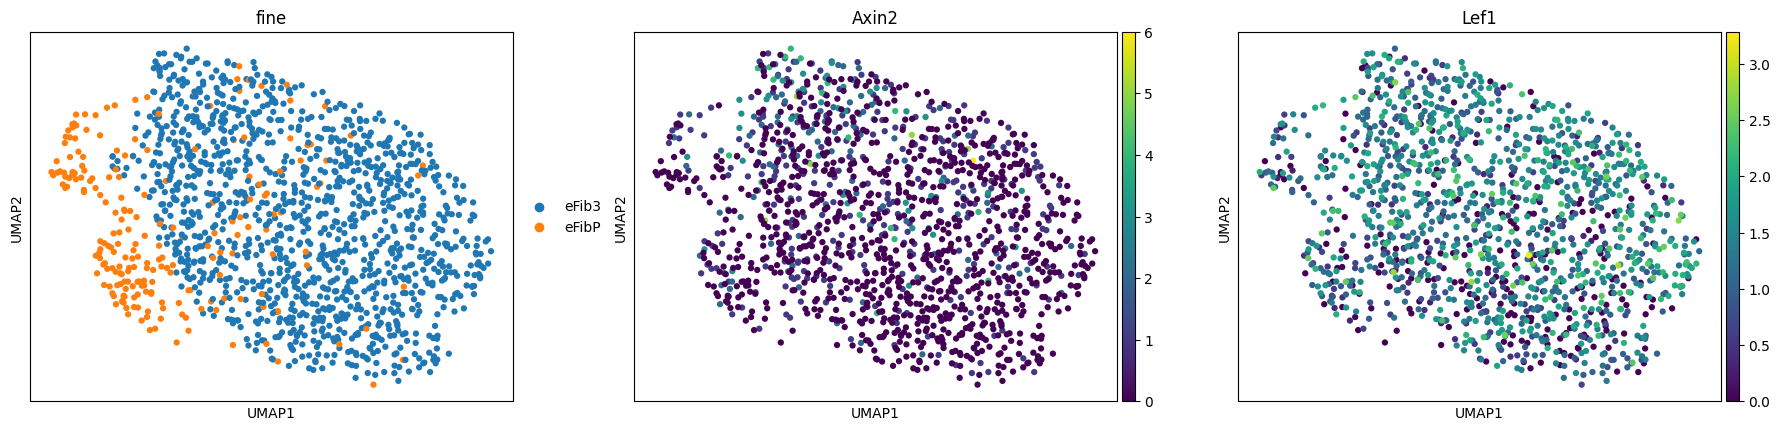

In [107]:
sc.pl.umap(a, color=["fine","Axin2","Lef1"])

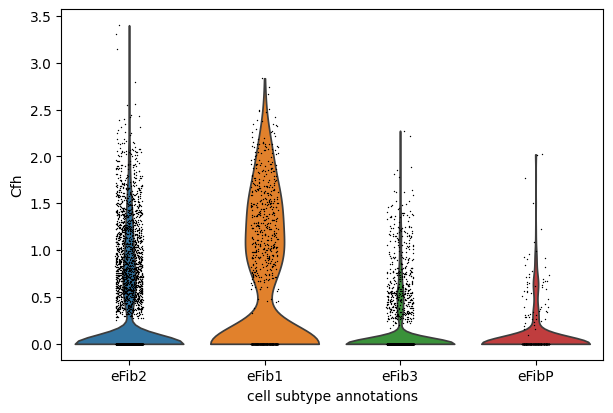

In [14]:
sc.pl.violin(fib_un, "Cfh", groupby="cell_subtype_annotations", use_raw=False, layer="log1p")

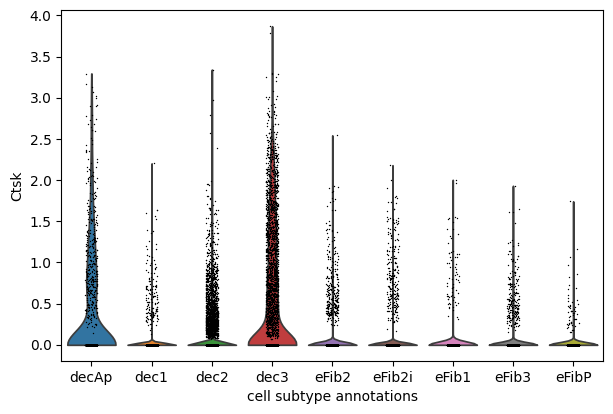

In [17]:
sc.pl.violin(adata, "Ctsk", groupby="cell_subtype_annotations", use_raw=False, layer="log1p")

In [18]:
fib_un_full = adata[(adata.obs['timepoint'] == 'uninduced')].copy()

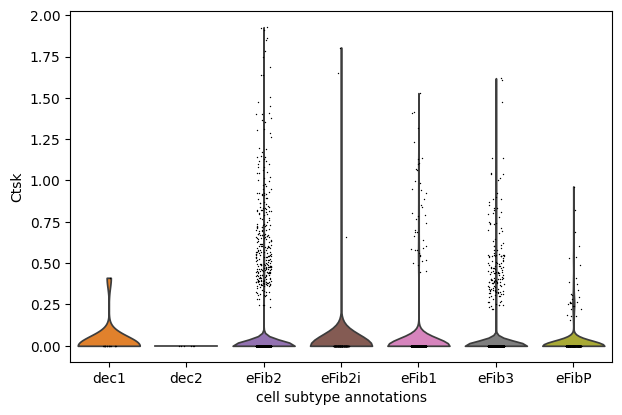

In [19]:
sc.pl.violin(fib_un_full, "Ctsk", groupby="cell_subtype_annotations", use_raw=False, layer="log1p")